# 01- Análisis Exploratorio de Datos

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

Objetivo:
Explorar el dataset proporcionado para comprender su estructura, analizar las variables numéricas y categóricas, y estudiar su relación con la variable objetivo, con el fin de encontrar patrones y variables relevantes para el modelado.

## 0. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carga del dataset

In [2]:
df = pd.read_csv('../data/rendimiento_estudiantes.csv', sep=';')
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')

df.head()

Filas: 4424 | Columnas: 37


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [3]:
#tipos de datos y valores nulos
info = pd.DataFrame({
    'dtype': df.dtypes,
    'nulos': df.isnull().sum(),
    'únicos': df.nunique()
})

print(info.to_string())

                                     dtype  nulos  únicos
estado_civil                        object      0       6
modo_solicitud                      object      0      18
orden_solicitud                      int64      0       8
curso                               object      0      17
asistencia_diurna_vespertina        object      0       2
cualificacion_previa                object      0      17
nota_cualificacion_previa          float64      0     101
nacionalidad                        object      0      21
cualificacion_madre                 object      0      29
cualificacion_padre                 object      0      34
ocupacion_madre                     object      0      32
ocupacion_padre                     object      0      46
nota_admision                      float64      0     620
desplazado                          object      0       2
necesidades_educativas_especiales   object      0       2
deudor                              object      0       2
matricula_al_d

In [4]:
#separamos variables por tipo

vars_numericas = df.select_dtypes(include='number').columns.tolist()
vars_categoricas = df.select_dtypes(include='object').columns.tolist()
#excluimos el target
vars_categoricas = [i for i in vars_categoricas if i!= 'objetivo']

print(f"Variables numéricas ({len(vars_numericas)}): {vars_numericas}")
print(f"\nVariables categóricas ({len(vars_categoricas)}): {vars_categoricas}")


Variables numéricas (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Variables categóricas (17): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 2. Variable objetivo

             total  porcentaje %
objetivo                        
graduado      2209          49.9
abandono      1421          32.1
matriculado    794          17.9


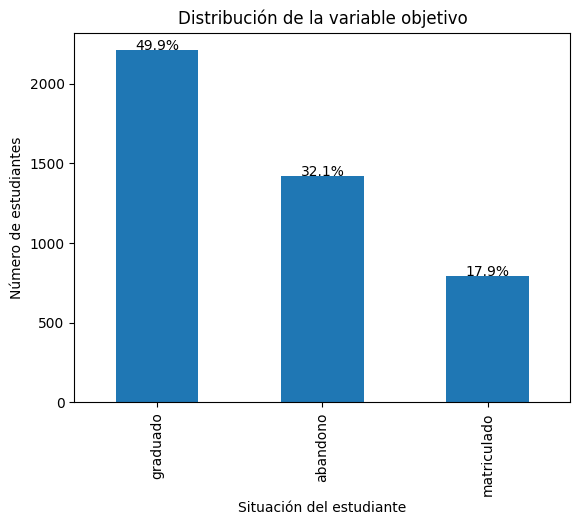

In [5]:
conteo = df['objetivo'].value_counts()
porcentaje = df['objetivo'].value_counts(normalize=True) * 100

vista_obj = pd.DataFrame({'total': conteo, 'porcentaje %': porcentaje.round(1)})
print(vista_obj)

#creamos gráfico para visualizarlo
plt.figure()

conteo.plot(kind='bar')

#añadimos porcentajes encima
for i,v in enumerate(conteo.values):
    plt.text(i, v, f"{porcentaje.values[i]:.1f}%", ha='center')

plt.title('Distribución de la variable objetivo')
plt.xlabel('Situación del estudiante')
plt.ylabel('Número de estudiantes')

#la guardamos en figuras
plt.savefig('../figuras/distribucion_objetivo.png')
plt.show()

En la distribución de la variable objetivo vemos un ligero desbalanceo entre clases. La categoría mayoritaría (graduado) vemos casi el 50% de las observaciones, mientras que las otras dos clases presentantan proporciones del 32% y 18%, respectivamente.

Este desbalanceo, aunque no extremo, puede influir en el comportamiento de los modelos de clasificación que veremos más adelante, por lo que será importante tenerlo en cuenta al evaluar los resultados.

## 3. Variables numéricas

In [6]:
#estadísitcas descriptivas
df[vars_numericas].describe().round(2)

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.73,132.61,126.98,23.27,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,1.31,13.19,14.48,7.59,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,0.00,95.00,95.00,17.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,125.00,117.90,19.00,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,133.10,126.10,20.00,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,2.00,140.00,134.80,25.00,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,9.00,190.00,190.00,70.00,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


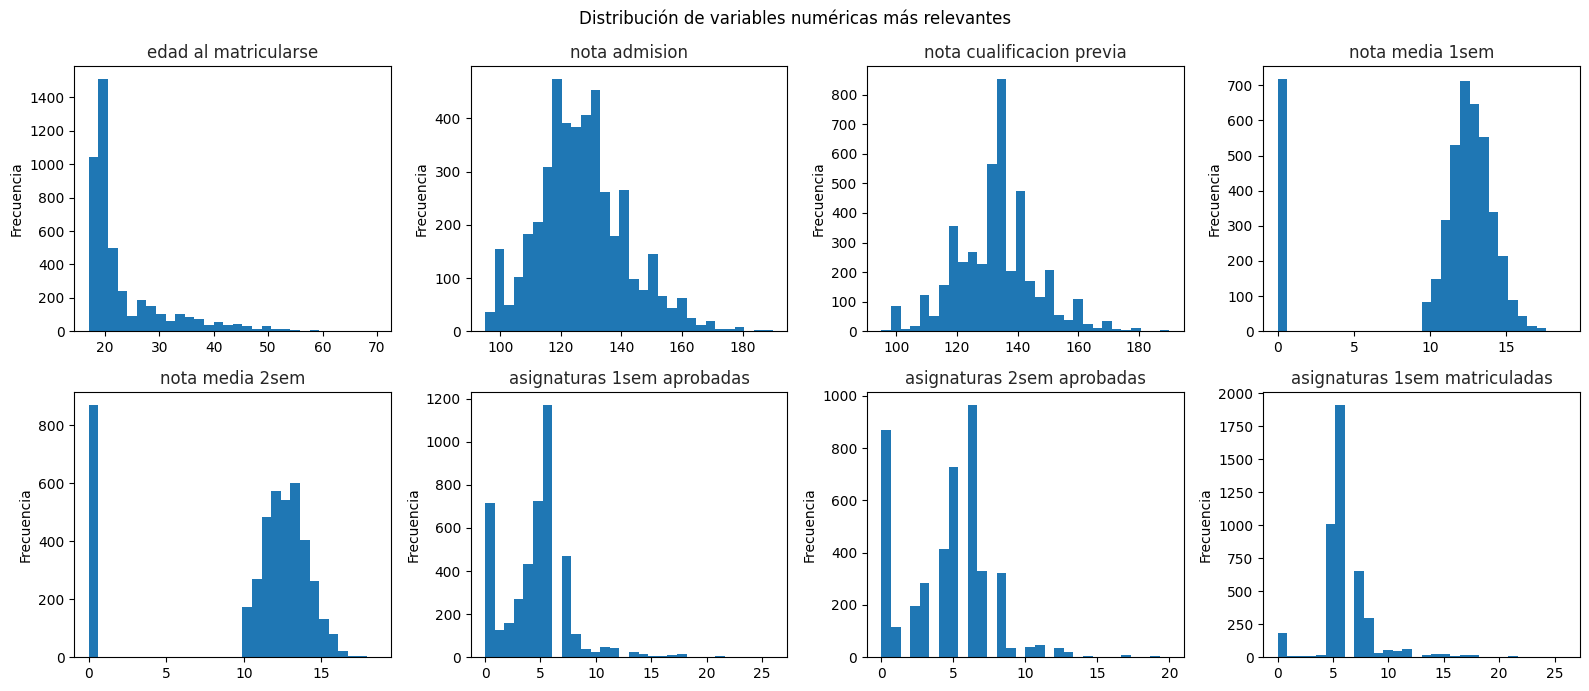

In [11]:
#vemos distribución de las variables numéricas más relevantes
vars_plot = [
    'edad_al_matricularse', 'nota_admision', 'nota_cualificacion_previa',
    'nota_media_1sem', 'nota_media_2sem',
    'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas', 'asignaturas_1sem_matriculadas'
]


fig, axes = plt.subplots(2,4, figsize=(16,7))
axes = axes.flatten()

for i,var in enumerate(vars_plot):
    axes[i].hist(df[var].dropna(), bins=30)
    axes[i].set_title(var.replace('_', ' '), alpha=0.85) #mantenemos los titulos sin el _
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')



#ocultar si sale algún subplot vacío
for j in range(len(vars_plot), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribución de variables numéricas más relevantes')
plt.tight_layout()
plt.savefig('../figuras/histogramas_numericas.png')
plt.show()


Vemos que las variables numéricas presentan distribuciones heterogéneas. Algunas, como la edad al matricularse, muestran una distribución asimétrica con cola derecha, indicando que la mayoría de estudiantes accede joven pero exite un grupo relevante de incoporación más tardía. Las notas de admision y cualificación previa, se distribuyen de forma aproximadamente unimodal, con cierta concentración en valores medios-altos. 
Por último las variables relacionadas con los notas medias de los distintos semestres muestran distribuciones bimodales o con piso en cero, lo que refleja estudiantes con rendimiento nulo (seguramente porque llegarían a abandonar sin examinarse). tsmbién lo indica el crecimiento de las asignaturas aprobadas = 0 del 1er semestre al segundo, por el posible abandono

## 4. Relación variables numéricas y objetivo

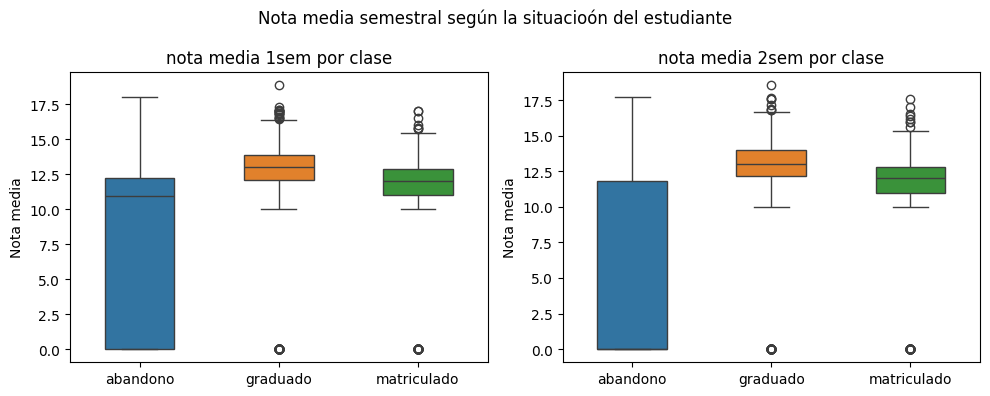

In [ ]:
#boxplots de las notas medias
fig, axes = plt.subplots(1,2, figsize=(10,4))

for ax, var in zip(axes, ['nota_media_1sem', 'nota_media_2sem']):
    sns.boxplot(data=df, x='objetivo', y=var, hue='objetivo', legend=False, ax= ax, width=0.5)
    ax.set_title(f'{var.replace("_", " ")} por clase')
    ax.set_xlabel('')
    ax.set_ylabel('Nota media')

fig.suptitle('Nota media semestral según la situación del estudiante')
plt.tight_layout()
plt.savefig('../figuras/boxplot_notas_por_clase.png')
plt.show()

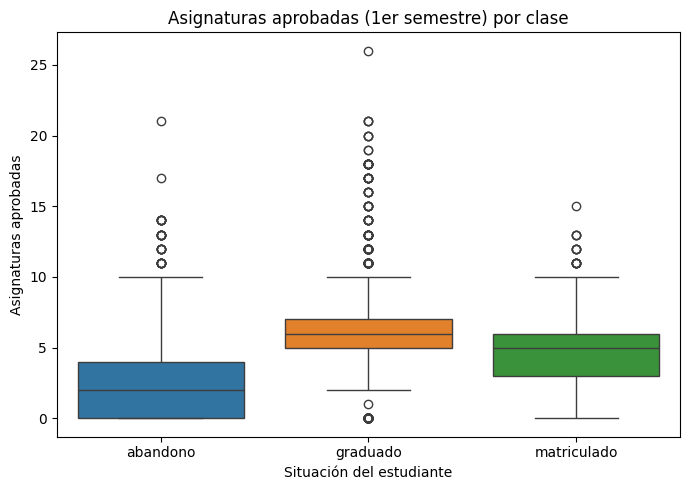

In [8]:
#boxplot: asignaturas aprobadas 1er semestre por clse

plt.figure(figsize=(7,5))

sns.boxplot(data=df, x='objetivo', y='asignaturas_1sem_aprobadas', hue='objetivo', legend=False)
plt.title('Asignaturas aprobadas (1er semestre) por clase')
plt.xlabel('Situación del estudiante')
plt.ylabel('Asignaturas aprobadas')


plt.tight_layout()
plt.savefig('../figuras/boxplot_aprobadas_1sem.png')
plt.show()

In [ ]:
#medianas por clase para cuantificar las diferencias
medians = df.groupby('objetivo')[['nota_media_1sem', 'nota_media_2sem', 'asignaturas_1sem_aprobadas']].median().round(2)
print("Medianas por clase: ")
print(medians)

Medianas por clase: 
             nota_media_1sem  nota_media_2sem  asignaturas_1sem_aprobadas
objetivo                                                                 
abandono               10.93              0.0                         2.0
graduado               13.00             13.0                         6.0
matriculado            12.00             12.0                         5.0


Observamos diferencias claras entre las clases en las variables de rendimiento académico. El dato más llamativo lo vemos en la tabla de medianas: la nota_media_2sem para el grupo de abandono es 0, lo que indica que menos de la mitd de los estudiantes que abandonnan no llegan a obtener calificación el segundo semestre, confirmando nuestra hipótesis de que han dejado los estudios antes de examinarse de un cuatrimestre a otro (tambien las asignaturas del 1sem aprobadas, cuya mediana es 2).

En contraste, graduados y matriculados presentan medianas de 13 y 12, respectivamente, sin diferencias sustanciales entre ellos en las notas.

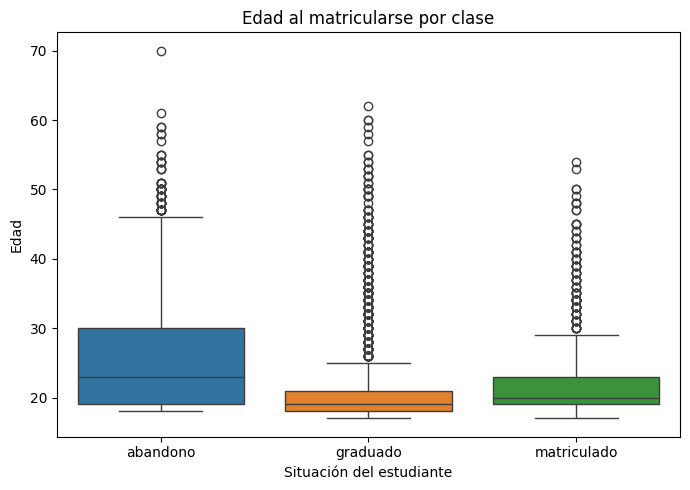

In [13]:
#boxplot edad
plt.figure(figsize=(7,5))

sns.boxplot(data=df, x='objetivo', y='edad_al_matricularse', hue='objetivo', legend=False)
plt.title('Edad al matricularse por clase')
plt.xlabel('Situación del estudiante')
plt.ylabel('Edad')
plt.tight_layout()
plt.savefig('../figuras/boxplot_edad_por_clase.png')
plt.show()

Respecto a la edad, los estudiantes que abandonan tienden a ser ligeramente mayores al matricularse, con mayor dispersión y más outliers en valores altos, lo que podría asociarse a dificultades de reincorporación al sistema universitario en edades más avanzadas

In [14]:
#analisis más profundo de outliers

vars_outliers = ['nota_media_1sem', 'nota_media_2sem', 'asignaturas_1sem_aprobadas','asignaturas_2sem_aprobadas' ]
resumen_outliers = []
for var in vars_outliers:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3-Q1
    n_outliers = ((df[var]<Q1 -1.5*IQR) | (df[var]> Q3 + 1.5*IQR)).sum()
    resumen_outliers.append({
        'variable': var, 'Q1': Q1, 'Q3': Q3,
        'IQR': round(IQR, 2), 'n_outliers': n_outliers,
        '%': round(n_outliers / len(df)*100, 1)
    })

print(pd.DataFrame(resumen_outliers).to_string(index=False))

                  variable    Q1        Q3  IQR  n_outliers    %
           nota_media_1sem 11.00 13.400000 2.40         726 16.4
           nota_media_2sem 10.75 13.333333 2.58         877 19.8
asignaturas_1sem_aprobadas  3.00  6.000000 3.00         180  4.1
asignaturas_2sem_aprobadas  2.00  6.000000 4.00          44  1.0


Por último, el análisis de Rango Intercuartílico para outliers nos muestra que las notas medias concentran la mayoría de outliers (16.4% en 1er semestre, 19.8% en 2º), mientras que las varibales de asignatuas aprobadas mucho menores (4.1% y 1%). Estos valores atípicos se situan principalmente en el extremo inferior y corresponden a estudiantes que abandonaron sin examinarse, lo que refleja comportamiento real. Hemos decidido por ello mantenerlos en el preprocesado para no sesgar el análisis preciamente hacia los perfiles de mayor interés, son muy informativos.

## 5. Relación variables categóricas y objetivo

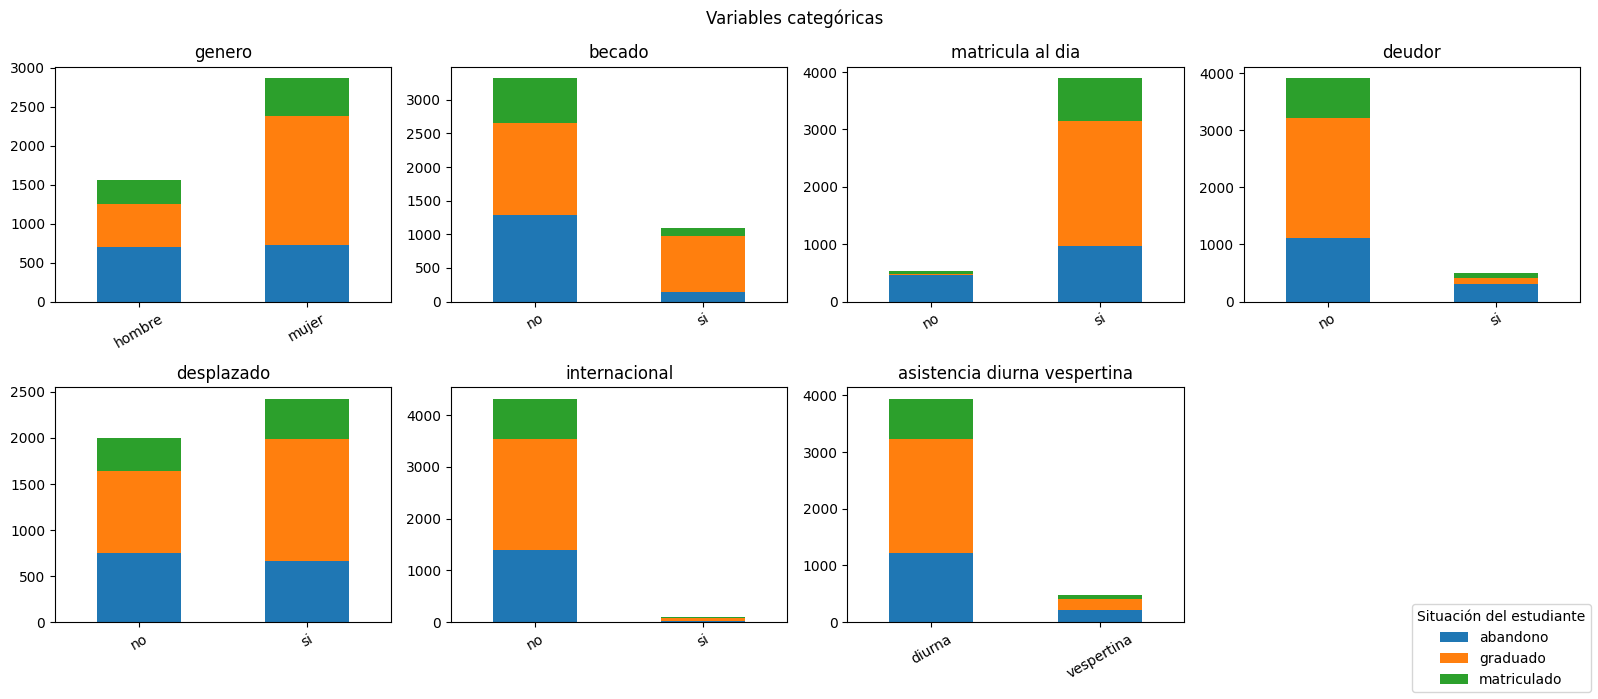

In [ ]:
#seleccionamos las más relevantes
vars_cat_plot = ['genero', 'becado', 'matricula_al_dia', 'deudor',
                 'desplazado', 'internacional','asistencia_diurna_vespertina']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

#las añadimso para hacer una leyenda comun
handles = None
labels = None

for i, var in enumerate(vars_cat_plot):
    tabla = df.groupby([var, 'objetivo']).size().unstack(fill_value=0)
    tabla.plot(kind= 'bar', stacked=True, ax= axes[i]) #asi ya vemos la relación con el target

    axes[i].set_title(var.replace('_', ' '))
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)

    #guardamos handles solo una vez
    if handles is None:
        handles, labels = axes[i].get_legend_handles_labels()

    #quitamos leyenda del subplot
    axes[i].get_legend().remove()

for j in range(len(vars_cat_plot), len(axes)):
    axes[j].set_visible(False)

fig.legend(handles, labels, title='Situación del estudiante', loc='lower right')

fig.suptitle('Variables categóricas')
plt.tight_layout()
plt.savefig('../figuras/stacks_categoricas_obj.png')
plt.show()


Las variables categóricas muestran patrones relevantes en relación con la situacion del estudiante.

En particular, facotres como estar becado, tener la matrícula al día o no ser deudor, se asocian con una mayor proporción de estudiantes graduados, mientras que en otros categorías aumenta el peso relativo del abandono.

Nos llama también especialmente la atención como muchos más estudiantes graduados son más mujeres que hombres, así como no internacionales a sí serlo.

## 6. Matriz de correlación (variables numéricas)

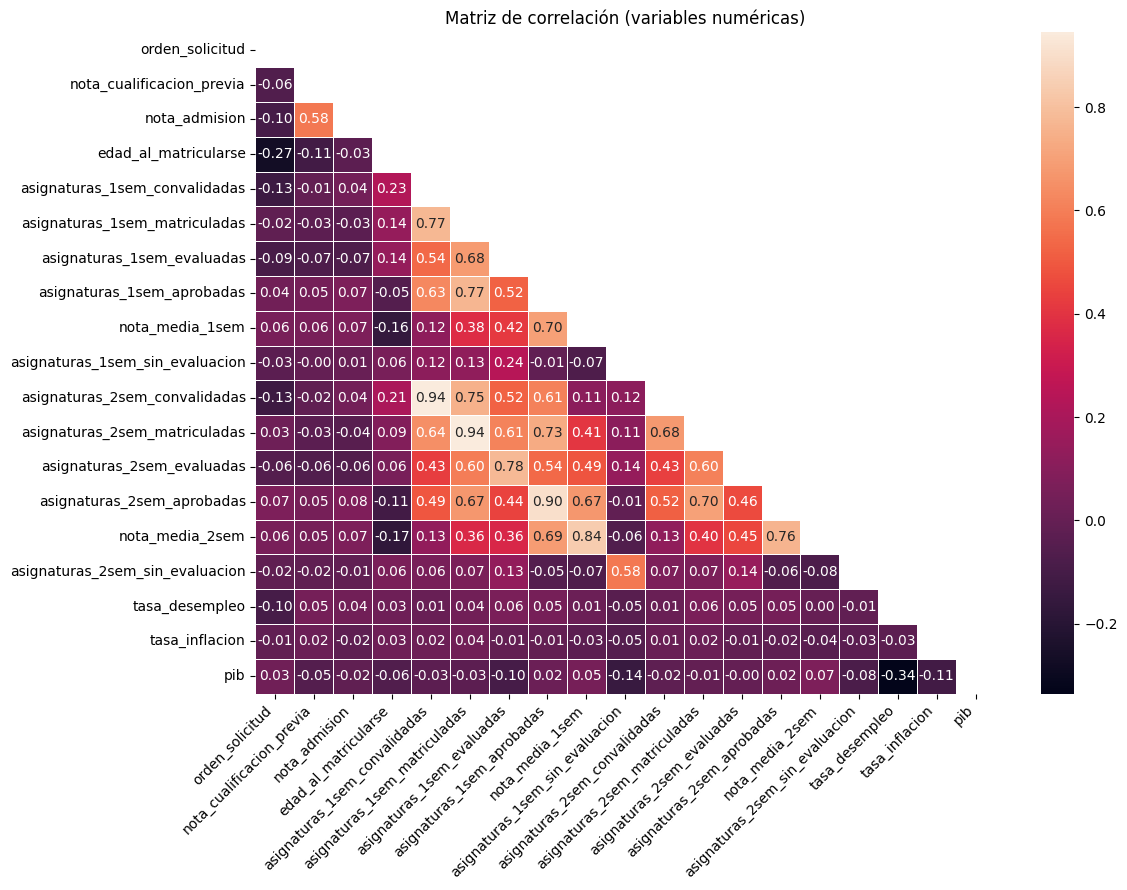

In [ ]:
corr = df[vars_numericas].corr()

fig, ax = plt.subplots(figsize =(12, 9))
#guardamos solo el triangulo inferior
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', linewidths=0.5, ax=ax)

ax.set_title('Matriz de correlación (variables numéricas)')
#para corregir el eje x se vea bien
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('../figuras/matriz_correlaciones.png')
plt.show()


La matriz de correlación muestra una fuerte relación entre las variables académicas, especialmente las notas medias y el número de asignaturas aprobadas.
Concretamente, vemos la correlación más fuerte entre las asignaturas del 1er y el 2º semestre convalidadas, y las matriculadas, con un 0.94. 
Por otro lado, los indicadores amcroeconómicos presentan correlaciones muy bajas, lo que sugiere una menor relevancia en la predicción del rendimiento académico.

## 7. Variables macroeconómicas

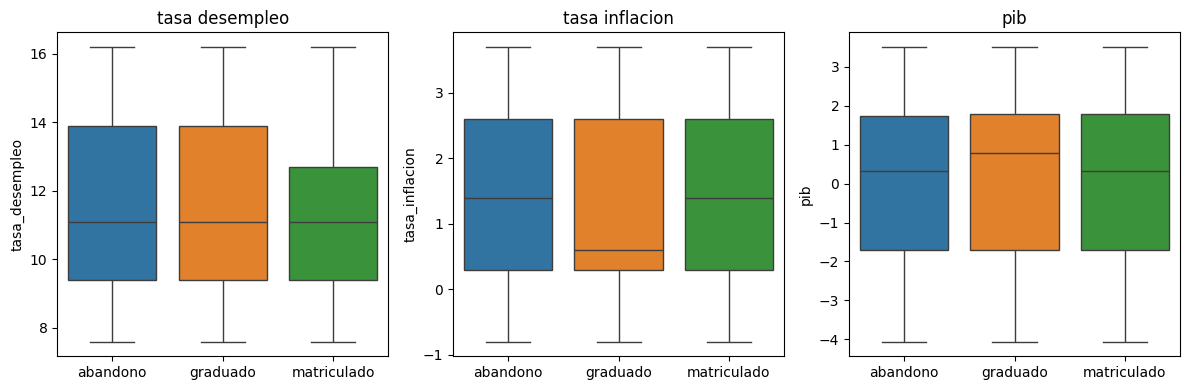

In [ ]:
#seleccionamos solo las variables relacionadas con temas económicos
macro = ['tasa_desempleo', 'tasa_inflacion', 'pib']

fig, axes = plt.subplots(1,3, figsize=(12, 4))

for ax, var in zip(axes, macro):
    sns.boxplot(data=df, x='objetivo', y=var, ax=ax, hue='objetivo', legend=False)
    ax.set_title(var.replace('_', ' '))
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig('../figuras/variables_macroeconomicas.png')
plt.show()

Las variables macroeconómicas no muestran diferencias claras entre las distintas clases de la variable objetivo.
Esto nos sugiere que estas variables tienen una capacidad discriminativa limitada a nivel individual.
En comparación con las variables académicas, su posible aportación a los modelos predictivos parece menor

## 8. Resumen EDA. Conclusiones para el informe

In [ ]:
print("--RESUMEN EDA--")

print(f"Nº estudiantes: {len(df)}")
print(f"Nº variables: {df.shape[1]}")
print(f"Valores nulos totales: {df.isnull().sum().sum()} ")

print(f"\nDistribución de clases: ")
for clase, pct in porcentaje.items():
    print(f" - {clase}: {pct:.1f}%")

print(f"\nCorrelaciones más altas con nota_media_2sem:")
print(corr['nota_media_2sem'].drop('nota_media_2sem').abs().sort_values(ascending=False).head(8))

print(f"\nNúmero variables numéricas: {len(vars_numericas)}")
print(f"\nNúmero variables categóricas: {len(vars_categoricas)}")


--RESUMEN EDA--
Nº estudiantes: 4424
Nº variables: 37
Valores nulos totales: 0 

Distribución de clases: 
 - graduado: 49.9%
 - abandono: 32.1%
 - matriculado: 17.9%

Correlaciones más altas con nota_media_2sem:
nota_media_1sem                  0.837170
asignaturas_2sem_aprobadas       0.760804
asignaturas_1sem_aprobadas       0.685560
asignaturas_2sem_evaluadas       0.453394
asignaturas_2sem_matriculadas    0.395135
asignaturas_1sem_matriculadas    0.361959
asignaturas_1sem_evaluadas       0.355036
edad_al_matricularse             0.173419
Name: nota_media_2sem, dtype: float64

Número variables numéricas: 19

Número variables categóricas: 17
